## 4. Modelling

In [1]:
import pandas as pd    
import numpy as np    
import os       
import warnings     
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt    
import seaborn as sns   

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler    
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, roc_curve, auc, roc_auc_score)
from xgboost import XGBClassifier   
from statsmodels.tsa.arima.model import ARIMA  



### Paths & Config

In [2]:

script_dir=os.path.dirname(os.path.abspath('__file__'))
project_dir=os.path.dirname(script_dir)
data_dir=os.path.join(project_dir, 'Data')
output_dir=os.path.join(project_dir, 'Model_outputs')
os.makedirs(output_dir, exist_ok=True)

input_path=os.path.join(data_dir, 'crime_features_model.csv')

#Size of test set
N_TEST_MONTHS=8

#Top 10% of 359 LSOAs
N_HOTSPOT=36
RANDOM_STATE=100

#Styling
sns.set_style('whitegrid')

#Defining feature columns
FEATURE_COLS=['crime_lag_1', 'crime_lag_2', 'crime_lag_3', 'crime_change', 'crime_rolling_3', 'hotspot_lag_1',
    'spatial_lag_crime', 'spatial_lag_hotspot', 'month_sin', 'month_cos',
    'temp_mean', 'temp_max', 'temp_min', 'rainfall_total', 'rainfall_days',
    'school_holiday_days', 'bank_holiday_days',
    'imd_decile', 'income_decile', 'employment_decile', 'education_decile',
    'health_decile', 'housing_decile', 'living_env_decile',
    'la_Hartlepool', 'la_Middlesbrough', 'la_Redcar and Cleveland', 'la_Stockton-on-Tees'
]

# Setting up dict to store results
results={}


### Loading data and creating forecasting target

In [3]:
df=pd.read_csv(input_path)
print(f"Loaded {len(df):,} rows, {df['Month'].nunique()} months, {df['LSOA code'].nunique()} LSOAs")

# Creating target: NEXT month's hotpot status
df=df.sort_values(['LSOA code', 'Month']).reset_index(drop=True)
df['hotspot_next']=df.groupby('LSOA code')['hotspot'].shift(-1)
df=df.dropna(subset=['hotspot_next']).copy()
df['hotspot_next']=df['hotspot_next'].astype(int)

print(f"After creating 'hotspot_next' target: {len(df):,} rows, {df['Month'].nunique()} months")
print(f"Target balance: hotspot_next=1 {df['hotspot_next'].sum()} ({df['hotspot_next'].mean()*100:.1f}%)")



Loaded 11,847 rows, 33 months, 359 LSOAs
After creating 'hotspot_next' target: 11,488 rows, 32 months
Target balance: hotspot_next=1 1152 (10.0%)


### Temporal train/test split 

The last 8 months will be in the test set to prevent the model training on future months and testing on previous months (i.e. train on Spetember - test on June).

In [4]:

months=sorted(df['Month'].unique())
#Defining train/test months 
train_months=months[:-N_TEST_MONTHS]
test_months=months[-N_TEST_MONTHS:]

#Copying the corresponding months data 
train=df[df['Month'].isin(train_months)].copy()
test=df[df['Month'].isin(test_months)].copy()

#Defining the train and test set
X_train, y_train=train[FEATURE_COLS], train['hotspot_next']
X_test, y_test=test[FEATURE_COLS], test['hotspot_next']

print(f"Train: {train_months[0]} to {train_months[-1]} ({len(train):,} rows)")
print(f"Test: {test_months[0]} to {test_months[-1]} ({len(test):,} rows)")




Train: 2023-07 to 2025-06 (8,616 rows)
Test: 2025-07 to 2026-02 (2,872 rows)


### Model 1: Persistence Baseline

In [5]:
print("MODEL 1: PERSISTENCE BASELINE")

#Target
pred_baseline=test['hotspot'].values

#CAlculating metrics
acc=accuracy_score(y_test,pred_baseline)
prec=precision_score(y_test, pred_baseline)
rec=recall_score(y_test, pred_baseline,zero_division=0)
f1=f1_score(y_test, pred_baseline,zero_division=0)

#Storing results
results['Persistence Baseline']={'accuracy':acc,
                                'precision':prec,
                                'recall':rec,
                                'f1':f1,
                                'auc':np.nan}

print("Results:")
print(f"Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f}")






MODEL 1: PERSISTENCE BASELINE
Results:
Accuracy: 0.947 | Precision: 0.736 | Recall: 0.736 | F1: 0.736


### Model 2: Logistic Regression

In [6]:
print("MODEL 2: LOGISTIC REGRESSION")

scaler=StandardScaler()
X_train_s=scaler.fit_transform(X_train)
X_test_s=scaler.transform(X_test)

lr=LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
lr.fit(X_train_s,y_train)
pred_lr=lr.predict(X_test_s)
proba_lr=lr.predict_proba(X_test_s)[:, 1]

acc=accuracy_score(y_test,pred_lr)
prec=precision_score(y_test, pred_lr, zero_division=0)
rec=recall_score(y_test, pred_lr,zero_division=0)
f1=f1_score(y_test, pred_lr,zero_division=0)
auc_score=roc_auc_score(y_test,proba_lr)

results['Logistic Regression']={'accuracy':acc,
                                'precision':prec,
                                'recall':rec,
                                'f1':f1,
                                'auc':auc_score}

print("Results:")
print(f"Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | AUC: {auc_score:.3f}")



MODEL 2: LOGISTIC REGRESSION
Results:
Accuracy: 0.924 | Precision: 0.576 | Recall: 0.934 | F1: 0.713 | AUC: 0.979


### MOodel 3: ARIMA (per-LSOA crime forecast --> hotspot threshold)

In [7]:
print("MODEL 3: ARIMA")
print("Fitting ARIMA(1,0,1) per LSOA for each test month")

warnings.filterwarnings('ignore')

#Reshaping from long (1 row per LSOA-month) to wide (months as rows, LSOAs as columns)
# --> each column is one LSOA's full time series - ARIMA format requirement
crime_wide=df.pivot_table(index='Month', columns='LSOA code',
                          values='crime_count').sort_index()

N_HOTSPOT=36

arima_rows=[]

#Expanding-window forecast, for each test month training on everything before it
for test_month in test_months:
    print(f"Forecasting: {test_month}...")
    #Finding this month's position and slicing all rows before it
    test_idx=list(crime_wide.index).index(test_month)
    train_series_all=crime_wide.iloc[:test_idx]

    preds={}

    for lsoa in crime_wide.columns:
        series=train_series_all[lsoa].dropna()
        #If there is too little history for ARIMA, falling back to the series mean
        if len(series)<6:
            preds[lsoa]=series.mean() if len(series)>0 else 0
            continue

        try:
            #Fitting a separate ARIMA (1,0,1) to this LSOA's history and forecasting one step
            fit=ARIMA(series.values, order=(1,0,1)).fit()
            #Floor at 0 (negative crime - meaningless)
            preds[lsoa]=max(0, fit.forecast(steps=1)[0])
        except:
            #Falling back to the series mean if ARIMA fails to converge
            preds[lsoa]=series.mean()


    #Ranking LSOAs by predicted crime count (top 36 become predicted hotspots)
    pred_series=pd.Series(preds).sort_values(ascending=False)
    hotspot_lsoas=set(pred_series.head(N_HOTSPOT).index)

    for lsoa in preds:
        arima_rows.append({'Month': test_month, 'LSOA code': lsoa,
                            'pred_arima': 1 if lsoa in hotspot_lsoas else 0})
    

arima_df=pd.DataFrame(arima_rows)

#Attaching predictions to the test set (unmatched default to 0)
test=test.merge(arima_df, on=['Month', 'LSOA code'], how='left')
test['pred_arima']=test['pred_arima'].fillna(0).astype(int)

#Calculating results (AUC is not available for ARIMA)
acc=accuracy_score(y_test, test['pred_arima'])
prec=precision_score(y_test, test['pred_arima'], zero_division=0)
rec=recall_score(y_test, test['pred_arima'], zero_division=0)
f1=f1_score(y_test, test['pred_arima'],zero_division=0)

#Storing results
results['ARIMA']={'accuracy':acc,
                  'precision':prec,
                  'recall':rec,
                  'f1':f1,
                  'auc':np.nan}


print("Results:")
print(f"Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f}")










MODEL 3: ARIMA
Fitting ARIMA(1,0,1) per LSOA for each test month
Forecasting: 2025-07...
Forecasting: 2025-08...
Forecasting: 2025-09...
Forecasting: 2025-10...
Forecasting: 2025-11...
Forecasting: 2025-12...
Forecasting: 2026-01...
Forecasting: 2026-02...
Results:
Accuracy: 0.953 | Precision: 0.767 | Recall: 0.767 | F1: 0.767


### Model 4: XGBoost (with hyperparameter tuning)


In [8]:
print("MODEL 4: XGBOOST (TUNED):")

#Setting XGBoost to weight the minority class higher (clas imbalance ratio ~9:1)
spw=(y_train==0).sum()/(y_train==1).sum()
print(f"scale_pos_weight (imbalance): {spw:.1f}")

# Inner validation split for tuning (last 6 months of train)
#Temporal splitting again as the tuning would see future months
val_months=sorted(train['Month'].unique())[-6:]
inner_train=train[~train['Month'].isin(val_months)]
inner_val=train[train['Month'].isin(val_months)]
Xi_tr, yi_tr=inner_train[FEATURE_COLS], inner_train['hotspot_next']
Xi_val, yi_val=inner_val[FEATURE_COLS], inner_val['hotspot_next']


#Varying configuration for tree depth,learning rate, ensemble size
param_grid=[
    {'n_estimators': 300, 'max_depth':4, 'learning_rate':0.05, 'subsample': 0.8, 'colsample_bytree':0.8},
    {'n_estimators': 400, 'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8},
    {'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.03, 'subsample': 0.7, 'colsample_bytree': 0.7},
    {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9},
    {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8},
    {'n_estimators': 600, 'max_depth': 5, 'learning_rate': 0.02, 'subsample': 0.8, 'colsample_bytree': 0.8},
]

print("Tuning parameters....")
#Searching the grid, keeping the combo with the best F1
#Not GridSearchCV, as it would shuffle and rotate the data -->training on future months, predicting on past months would happen
best_f1, best_params=0, None
for params in param_grid:
    m=XGBClassifier(**params, scale_pos_weight=spw, random_state=RANDOM_STATE, eval_metric='logloss')
    m.fit(Xi_tr, yi_tr)
    proba=m.predict_proba(Xi_val)[:,1]
    for thr in np.arange(0.3, 0.75, 0.05):
        f1=f1_score(yi_val, (proba>=thr).astype(int), zero_division=0)
        if f1>best_f1:
            best_f1, best_params=f1, params
print(f"Best params: {best_params}")

#REfitting the winning config on all training data (inner_train + inner_val)
xgb=XGBClassifier(**best_params, scale_pos_weight=spw, random_state=RANDOM_STATE, eval_metric='logloss')
xgb.fit(X_train, y_train)

#Fine-tuning the decision threshold on inner-val probabilities (a 0.025 step)
#Default 0.5 would over-predict the minority class givens scale_pos_weight
val_proba=xgb.predict_proba(Xi_val)[:,1]
best_thr, best_thr_f1=0.5, 0
for thr in np.arange(0.3, 0.75, 0.025):
    f1=f1_score(yi_val, (val_proba>=thr).astype(int), zero_division=0)
    if f1>best_thr_f1:
        best_thr_f1, best_thr=f1,thr
print(f"Optimal threshold: {best_thr:.3f}")


#Applying the tuned threshold to test set probabilities
proba_xgb=xgb.predict_proba(X_test)[:,1]
pred_xgb=(proba_xgb>=best_thr).astype(int)

acc=accuracy_score(y_test,pred_xgb)
prec=precision_score(y_test, pred_xgb, zero_division=0)
rec=recall_score(y_test, pred_xgb,zero_division=0)
f1=f1_score(y_test, pred_xgb,zero_division=0)
auc_score=roc_auc_score(y_test,proba_xgb)

#Storing the results
results['XGBoost (Tuned)']={'accuracy':acc,
                    'precision':prec,
                    'recall':rec,
                    'f1':f1,
                    'auc':auc_score}

print("Results:")
print(f"Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | AUC: {auc_score:.3f}")




MODEL 4: XGBOOST (TUNED):
scale_pos_weight (imbalance): 9.0
Tuning parameters....
Best params: {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8}
Optimal threshold: 0.725
Results:
Accuracy: 0.952 | Precision: 0.721 | Recall: 0.844 | F1: 0.778 | AUC: 0.980


### RESULTS SUMMARY

In [9]:
print("OVERALL RESULTS SUMMARY")

summary=pd.DataFrame(results).T[['accuracy', 'precision', 'recall', 'f1', 'auc']]
print(summary.round(3).to_string())
summary.to_csv(os.path.join(output_dir, 'model_results.csv'))

OVERALL RESULTS SUMMARY
                      accuracy  precision  recall     f1    auc
Persistence Baseline     0.947      0.736   0.736  0.736    NaN
Logistic Regression      0.924      0.576   0.934  0.713  0.979
ARIMA                    0.953      0.767   0.767  0.767    NaN
XGBoost (Tuned)          0.952      0.721   0.844  0.778  0.980


TRANSITION ANALYSIS


In [10]:
print("TRANSITION ANALYSIS")

#Flagging the rows where the area changed status
test['is_transition']=(test['hotspot'] !=test['hotspot_next']).astype(int)
#Total number of rows flipped
n_trans=test['is_transition'].sum()
#Newly emerging hotspot
n_emerging=((test['hotspot']==0) & (test['hotspot_next']==1)).sum()
#Coming out of hotspot (cooling down)
n_cooling=((test['hotspot']==1) & (test['hotspot_next']==0)).sum()

print(f"Test observations: {len(test)}")
print(f"Transitions: {n_trans} ({n_trans/len(test)*100:.1f}%) "
      f"[Emerging: {n_emerging}, Cooling: {n_cooling}]")

#Atatching each model's already-made predictions as columns
test['pred_baseline']=pred_baseline
test['pred_lr']=pred_lr
test['pred_xgb']=pred_xgb

trans_results={}
print(f"{'Model':<22} {'All Trans':>10} {'Emerging':>10} {'Cooling':>10}")

#looping through each model's prediction column and scoring it
#ONLY on flipped rows
for name, col in [('Persistence Baseline', 'pred_baseline'),
                  ('Logistic Regression', 'pred_lr'),
                  ('ARIMA', 'pred_arima'),
                    ('XGBoost (Tuned)', 'pred_xgb')]:
    # only the rows that transitioned
    t=test[test['is_transition']==1]

    #Acc on ALL transitions, how often the pred matched the truth
    all_acc=(t[col]==t['hotspot_next']).sum() / len(t)*100

    #Emerging rows (0 -> 1)
    e=test[(test['hotspot']==0) & (test['hotspot_next']==1)]
    #Accuracy on emerging rows ONLY (area was 0, then 1 in next month, model predicted 1 - correct) 
    em_acc=(e[col]==1).sum() / len(e)*100

    #Cooling rows (1 -> 0)
    c=test[(test['hotspot']==1) & (test['hotspot_next']==0)]
    #Accuracy on cooling rows ONLY (area was 1, then 0 in next month, model predicted 0 - correct)
    co_acc=(c[col]==0).sum() / len(c)*100

    #Storing the 3 accuracies
    trans_results[name]={'all': all_acc, 'emerging': em_acc, 'cooling': co_acc}
    print(f"{name:<22} {all_acc:>9.1f}% {em_acc:>9.1f}% {co_acc:>9.1f}%")


pd.DataFrame(trans_results).T.to_csv(os.path.join(output_dir, 'transition_results.csv'))



TRANSITION ANALYSIS
Test observations: 2872
Transitions: 152 (5.3%) [Emerging: 76, Cooling: 76]
Model                   All Trans   Emerging    Cooling
Persistence Baseline         0.0%       0.0%       0.0%
Logistic Regression         40.8%      75.0%       6.6%
ARIMA                       50.0%      42.1%      57.9%
XGBoost (Tuned)             41.4%      50.0%      32.9%


### PLOT 1: MODEL COMPARISON

Plot 1 Model comparison:


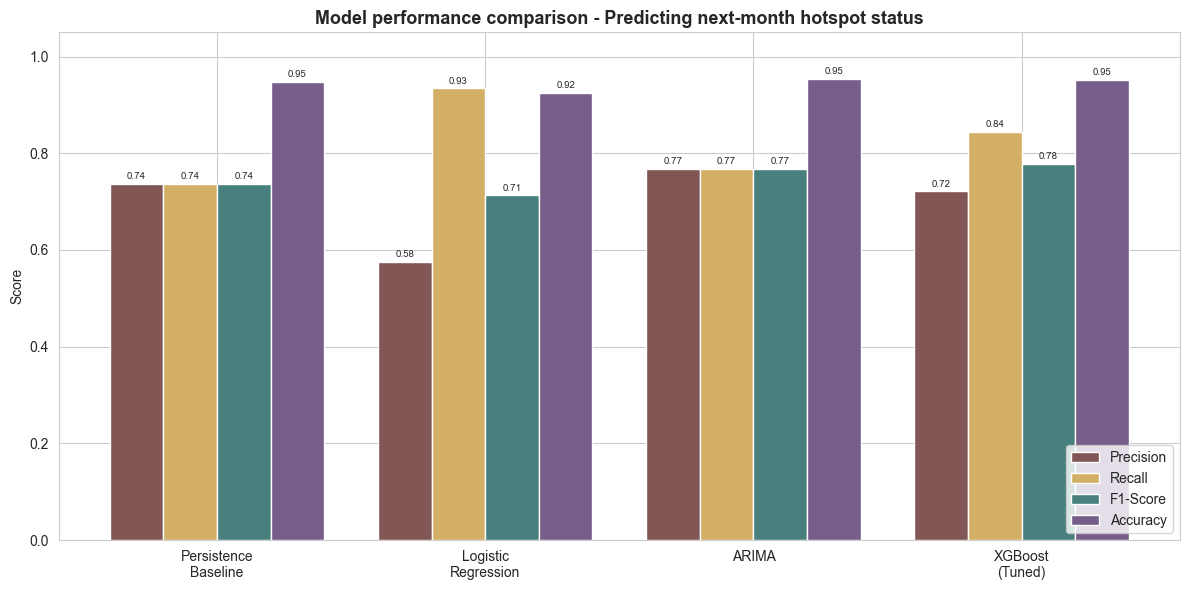

In [11]:
print("Plot 1 Model comparison:")

metrics={'Precision': [], 'Recall':[], 'F1-Score':[], 'Accuracy':[]}
model_names=['Persistence\nBaseline', 'Logistic\nRegression', 'ARIMA', 'XGBoost\n(Tuned)']
for key in ['Persistence Baseline', 'Logistic Regression', 'ARIMA', 'XGBoost (Tuned)']:
    metrics['Precision'].append(results[key]['precision'])
    metrics['Recall'].append(results[key]['recall'])
    metrics['F1-Score'].append(results[key]['f1'])
    metrics['Accuracy'].append(results[key]['accuracy'])

x=np.arange(len(model_names))
width=0.2

fig,ax=plt.subplots(figsize=(12,6))
colors=["#815654", "#d3af66", "#48807E", "#775d89"]

for i, (metric,values) in enumerate(metrics.items()):
    ax.bar(x+i*width, values, width, label=metric, color=colors[i], edgecolor='white')
    for j,v in enumerate(values):
        ax.text(x[j] + i*width, v+0.01, f'{v:.2f}', ha="center", fontsize=7)

ax.set_xticks(x+width*1.5)
ax.set_xticklabels(model_names)
ax.set_ylabel('Score')
ax.set_title('Model performance comparison - Predicting next-month hotspot status',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
ax.set_ylim(0,1.05)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_1_model_comparison.png'), dpi=150)
plt.show()

### PLOT 2: TRANSITION DETECTION



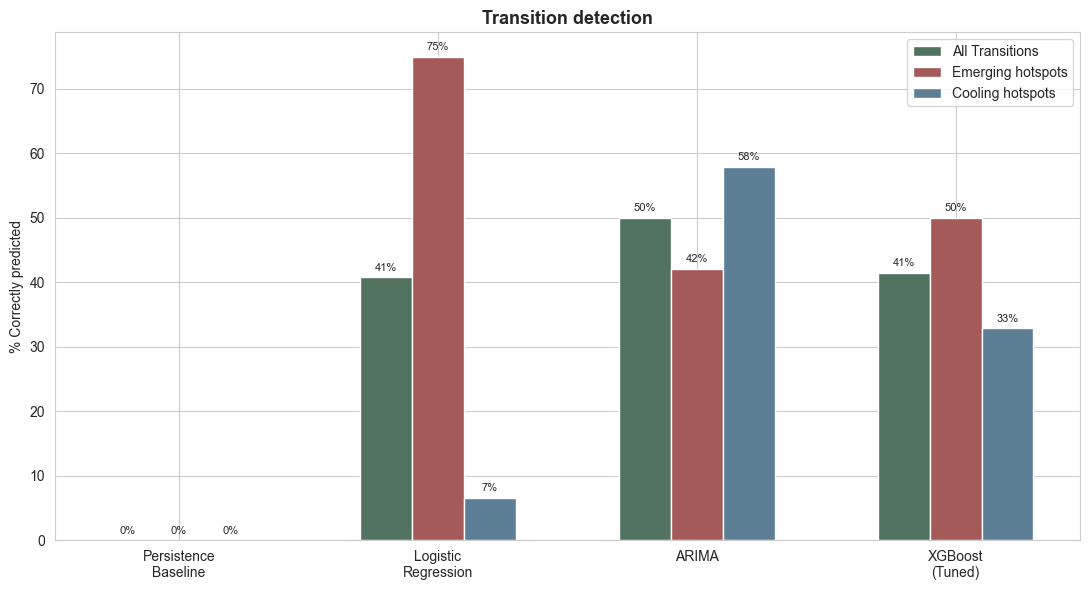

In [12]:

x=np.arange(4)
width=0.2

fig,ax=plt.subplots(figsize=(11,6))
tr_models=['Persistence Baseline','Logistic Regression','ARIMA', 'XGBoost (Tuned)']
labels=['Persistence\nBaseline', 'Logistic\nRegression', 'ARIMA', 'XGBoost\n(Tuned)']
all_t=[trans_results[m]['all'] for m in tr_models]
em_t=[trans_results[m]['emerging'] for m in tr_models]
co_t=[trans_results[m]['cooling'] for m in tr_models]

ax.bar(x-width, all_t, width, label='All Transitions', color="#527260", edgecolor='white')
ax.bar(x, em_t, width, label='Emerging hotspots', color="#a55a5a", edgecolor='white')
ax.bar(x+width, co_t, width, label='Cooling hotspots', color="#5c7f96", edgecolor='white')
for i in range(4):
    ax.text(x[i]-width, all_t[i]+1, f'{all_t[i]:.0f}%', ha='center',fontsize=8)
    ax.text(x[i], em_t[i]+1, f'{em_t[i]:.0f}%', ha='center', fontsize=8)
    ax.text(x[i]+width, co_t[i]+1, f'{co_t[i]:.0f}%', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('% Correctly predicted')
ax.set_title('Transition detection', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_2_transition_detection.png'), dpi=150)
plt.show()





### PLOT 3: FEATURE IMPORTANCE (XGBoost)

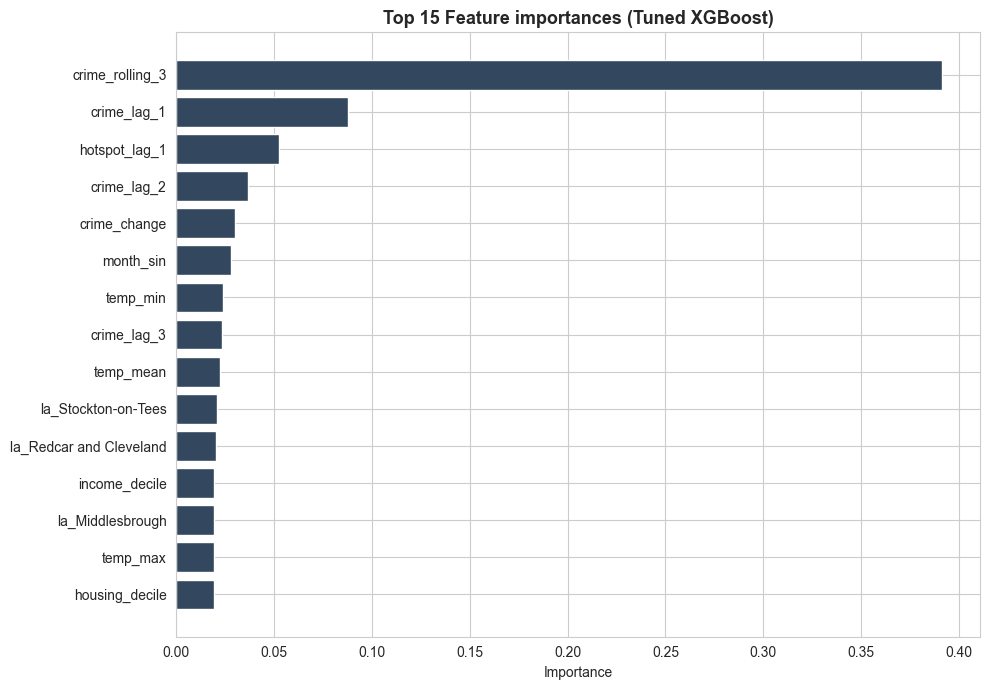

In [13]:
#Feature importance 
importance=pd.DataFrame({
    'feature': FEATURE_COLS, 'importance': xgb.feature_importances_
}).sort_values('importance', ascending=False).head(15)

#Saving 
importance.to_csv(os.path.join(output_dir, 'feature_importance.csv'), index=False)

fig,ax=plt.subplots(figsize=(10,7))
ax.barh(range(len(importance)), importance['importance'], color="#33485e", edgecolor='white')
ax.set_yticks(range(len(importance)))
ax.set_yticklabels(importance['feature'])
ax.invert_yaxis()
ax.set_xlabel('Importance')
ax.set_title('Top 15 Feature importances (Tuned XGBoost)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_03_feature_importance.png'), dpi=150)
plt.show()


### PLOT 4: CONFUSION MATRICES

ARIMA is excluded from the confusion-matrix as it is a point-forecast model not a native classifier.

Plot 4: Confusion matrices:


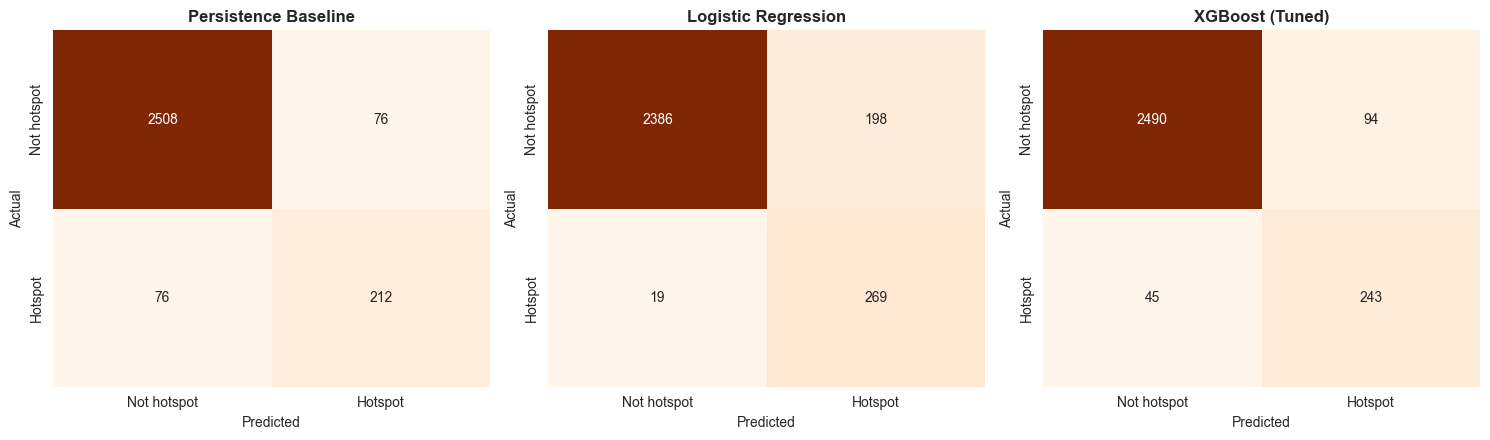

In [14]:
print("Plot 4: Confusion matrices:")

fig,axes=plt.subplots(1,3,figsize=(15,4.5))
for ax, (name,pred) in zip(axes, [
    ('Persistence Baseline', pred_baseline),
    ('Logistic Regression', pred_lr),
    ('XGBoost (Tuned)', pred_xgb)
]):
    cm=confusion_matrix(y_test,pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax, cbar=False,
                xticklabels=['Not hotspot', 'Hotspot'],
                yticklabels=['Not hotspot', 'Hotspot'])
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_4_confusion_matrices.png'), dpi=150)
plt.show()

### PLOT 5: ROC CURVES

Plot 5: ROC curves


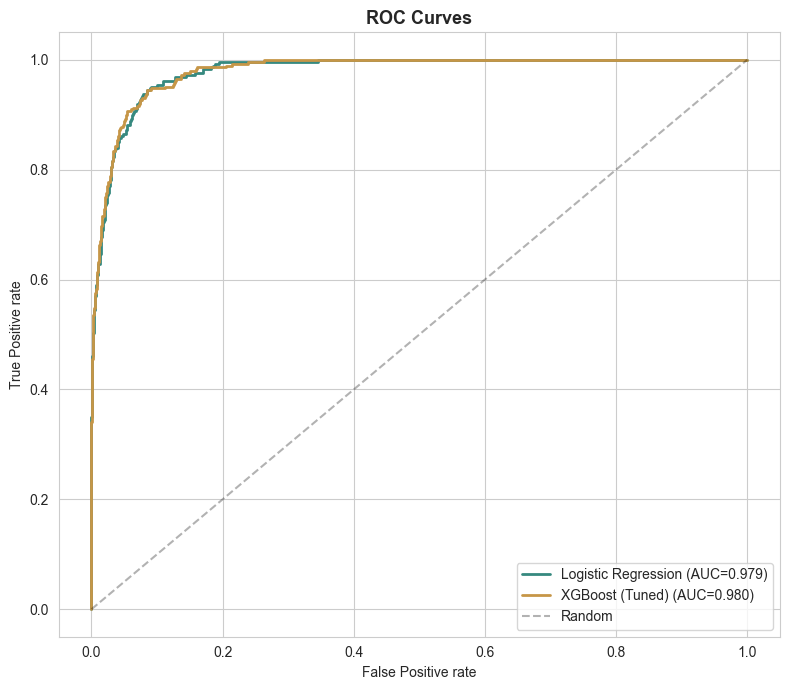

In [15]:
print("Plot 5: ROC curves")

fig,ax=plt.subplots(figsize=(8,7))
for name, proba, color in [('Logistic Regression', proba_lr, "#36897f"),
                           ('XGBoost (Tuned)', proba_xgb, "#c69647")]:
    fpr, tpr, _=roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC={auc(fpr,tpr):.3f})')

ax.plot([0,1], [0,1], 'k--', alpha=0.3, label='Random')
ax.set_xlabel('False Positive rate')
ax.set_ylabel('True Positive rate')
ax.set_title('ROC Curves', fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Plot_05_roc_curves.png'), dpi=150)
plt.show()

